In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from pathlib import Path

IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)

DATA_PATH = "C:/Users/Martin/Desktop/ecb-macroeconomic-analysis/data/macro_data.csv"

macro_data = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"]
)

macro_data = macro_data.sort_values("date").reset_index(drop=True)

print("Dataset overview:")
print(f"Observations: {len(macro_data)}")
print(f"Period: {macro_data['date'].min().date()} "
      f"to {macro_data['date'].max().date()}")
print()

target_variable = "ECB_Deposit_Rate"

indicator_variables = [
    "Inflation_HICP",
    "Core_Inflation",
    "Unemployment",
    "Industrial",
    "Brent_Oil_Price",
    "EUR_USD",
    "Economic_Sentiment"
]


Dataset overview:
Observations: 318
Period: 2000-01-31 to 2026-06-30



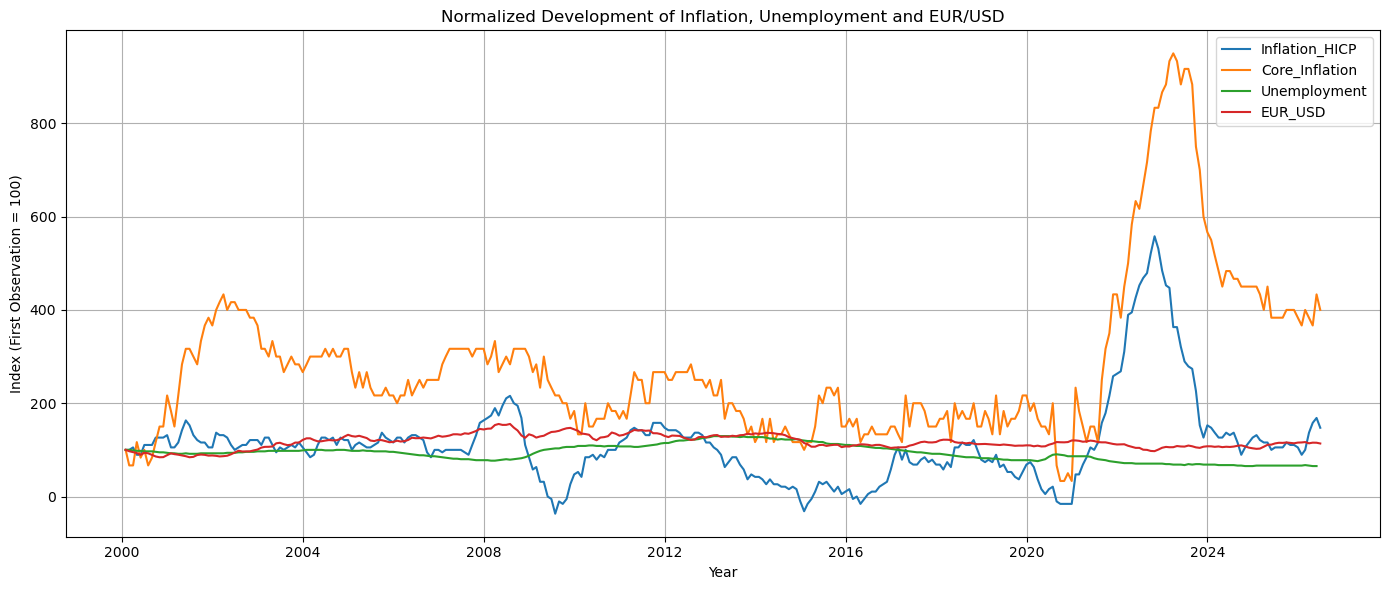

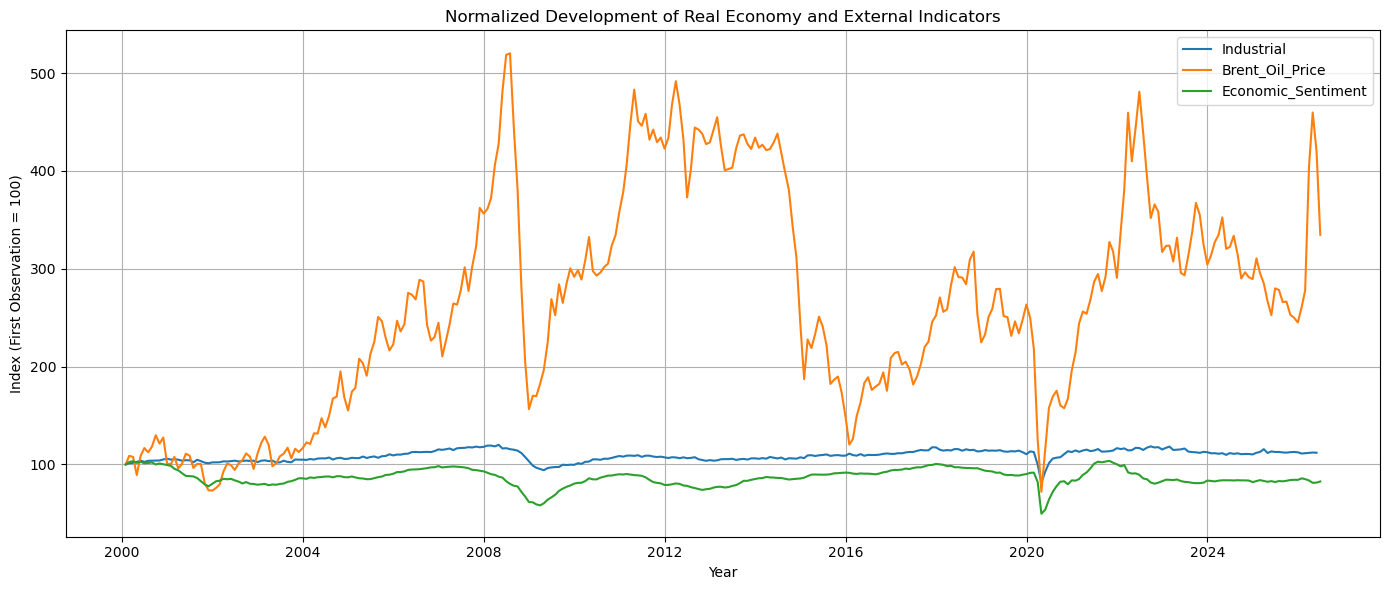

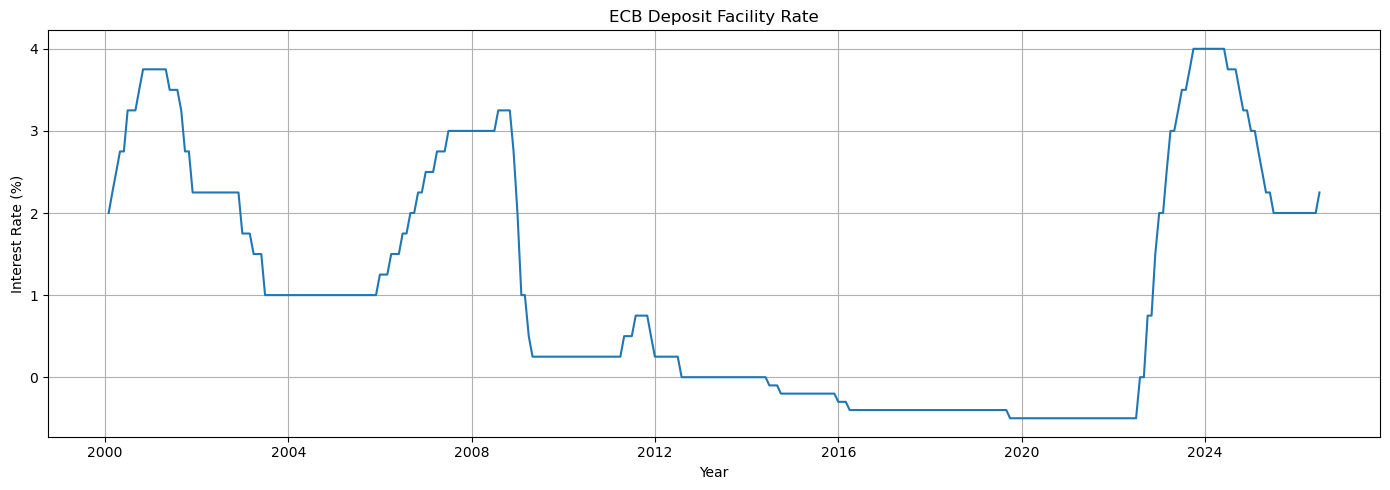

In [18]:
def normalize(series):
    """Normalize a series to 100 at its first observation."""
    return (series / series.iloc[0]) * 100


#Inflation, unemployment and exchange rate
variables_group1 = [
    "Inflation_HICP",
    "Core_Inflation",
    "Unemployment",
    "EUR_USD"
]

plt.figure(figsize=(14, 6))

for variable in variables_group1:
    plt.plot(
        macro_data["date"],
        normalize(macro_data[variable]),
        label=variable
    )

plt.title("Normalized Development of Inflation, Unemployment and EUR/USD")
plt.xlabel("Year")
plt.ylabel("Index (First Observation = 100)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(
    IMAGE_DIR / "inflation_unemployment_eurusd.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


#Industrial production, oil prices and sentiment
variables_group2 = [
    "Industrial",
    "Brent_Oil_Price",
    "Economic_Sentiment"
]

plt.figure(figsize=(14, 6))

for variable in variables_group2:
    plt.plot(
        macro_data["date"],
        normalize(macro_data[variable]),
        label=variable
    )

plt.title("Normalized Development of Real Economy and External Indicators")
plt.xlabel("Year")
plt.ylabel("Index (First Observation = 100)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ECB deposit facility rate
plt.figure(figsize=(14, 5))

plt.plot(
    macro_data["date"],
    macro_data[target_variable]
)

plt.title("ECB Deposit Facility Rate")
plt.xlabel("Year")
plt.ylabel("Interest Rate (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:

# 3. OLS Regression
regression_data = macro_data[
    [target_variable] + indicator_variables
].dropna()

y = regression_data[target_variable]
X = regression_data[indicator_variables]

X = sm.add_constant(X)

model_ols = sm.OLS(y, X).fit()

print("\nOLS Regression Results:")
print(model_ols.summary())



OLS Regression Results:
                            OLS Regression Results                            
Dep. Variable:       ECB_Deposit_Rate   R-squared:                       0.409
Model:                            OLS   Adj. R-squared:                  0.396
Method:                 Least Squares   F-statistic:                     30.58
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           4.86e-32
Time:                        20:28:05   Log-Likelihood:                -481.54
No. Observations:                 317   AIC:                             979.1
Df Residuals:                     309   BIC:                             1009.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const      


OLS Regression with HAC Standard Errors:
                            OLS Regression Results                            
Dep. Variable:       ECB_Deposit_Rate   R-squared:                       0.409
Model:                            OLS   Adj. R-squared:                  0.396
Method:                 Least Squares   F-statistic:                     12.10
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           1.16e-13
Time:                        20:28:05   Log-Likelihood:                -481.54
No. Observations:                 317   AIC:                             979.1
Df Residuals:                     309   BIC:                             1009.
Df Model:                           7                                         
Covariance Type:                  HAC                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------

C:\Users\Martin\AppData\Local\Temp\ipykernel_6280\1398815119.py:12: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(fig)


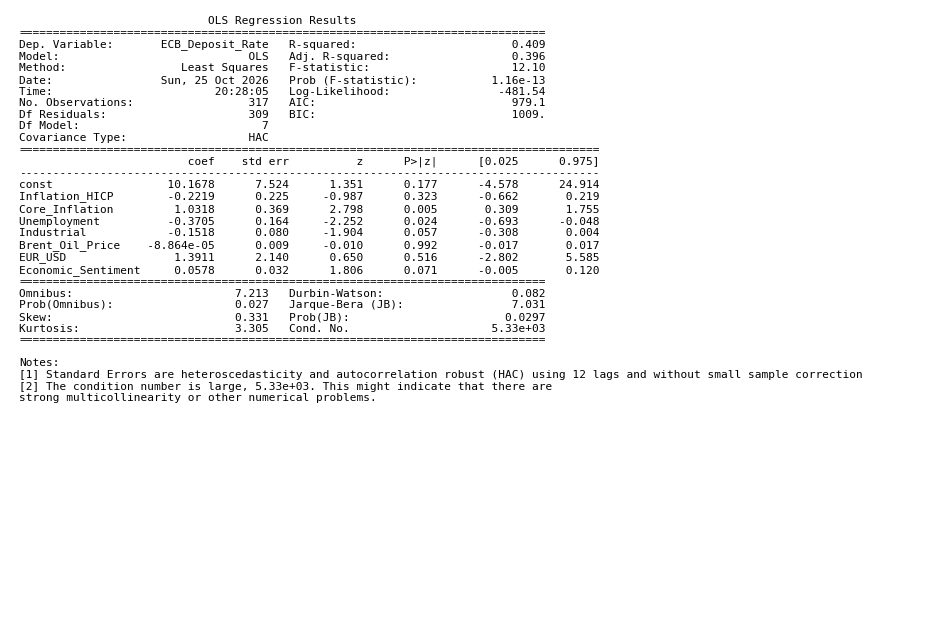

In [20]:
#HAC / Newey-West Standard Errors
model_hac = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

print("\nOLS Regression with HAC Standard Errors:")
print(model_hac.summary())


fig = model_hac.summary().as_html()
tables = pd.read_html(fig)
results_table = tables[0]

fig, ax = plt.subplots(figsize=(12, 8))
ax.axis("off")

ax.text(
    0.01, 0.99,
    model_hac.summary().as_text(),
    transform=ax.transAxes,
    fontsize=8,
    verticalalignment="top",
    fontfamily="monospace"
)

plt.savefig(
    IMAGE_DIR / "ols_hac_results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Lagged Correlations in Levels:
                    0M Lag  3M Lag  6M Lag  12M Lag
Inflation_HICP       0.298   0.189   0.093   -0.041
Core_Inflation       0.490   0.430   0.362    0.230
Unemployment        -0.464  -0.435  -0.393   -0.288
Industrial           0.055  -0.028  -0.120   -0.265
Brent_Oil_Price     -0.137  -0.173  -0.196   -0.233
EUR_USD             -0.231  -0.207  -0.176   -0.075
Economic_Sentiment  -0.016  -0.128  -0.229   -0.357

Lagged Correlations in Monthly Changes:
                    0M Lag  3M Lag  6M Lag  12M Lag
Inflation_HICP       0.018  -0.087  -0.094   -0.138
Core_Inflation       0.072   0.014  -0.000   -0.061
Unemployment        -0.307  -0.241  -0.170   -0.060
Industrial           0.110  -0.007  -0.042   -0.046
Brent_Oil_Price     -0.030  -0.095  -0.007   -0.036
EUR_USD             -0.022  -0.056  -0.122    0.033
Economic_Sentiment   0.068  -0.055  -0.082   -0.069


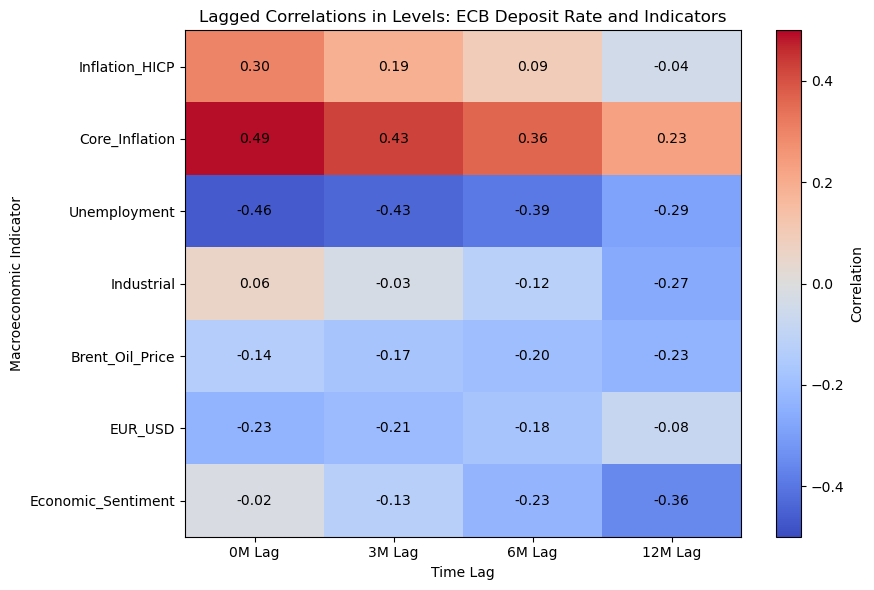

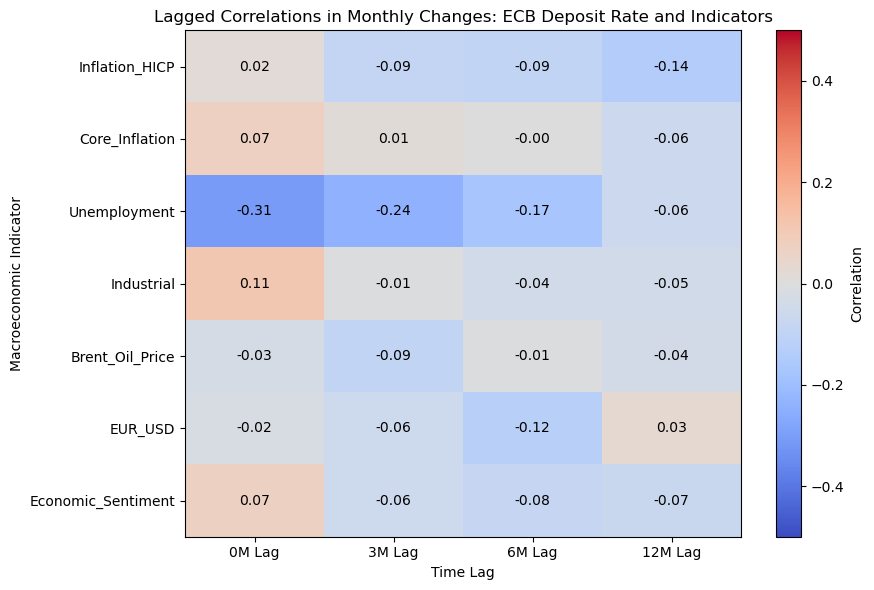

In [ ]:
#Lagged Correlations in Levels

lags = [0, 3, 6, 12]

def calculate_lag_correlations(data, variables, lags):
    """
    Calculate correlations between the current ECB deposit rate
    and current or future values of each indicator.

    A positive lag k compares rate[t] with indicator[t + k].
    """
    results = pd.DataFrame(
        index=variables,
        columns=[f"{lag}M Lag" for lag in lags],
        dtype=float
    )

    for variable in variables:
        for lag in lags:
            future_indicator = data[variable].shift(-lag)

            results.loc[variable, f"{lag}M Lag"] = (
                data[target_variable].corr(future_indicator)
            )

    return results


lag_results = calculate_lag_correlations(
    macro_data,
    indicator_variables,
    lags
)

print("\nLagged Correlations in Levels:")
print(lag_results.round(3))

# Monthly Changes
change_data = macro_data[
    [target_variable] + indicator_variables
].diff()

change_lag_results = calculate_lag_correlations(
    change_data,
    indicator_variables,
    lags
)

print("\nLagged Correlations in Monthly Changes:")
print(change_lag_results.round(3))



def plot_correlation_heatmap(results, title, filename):
    """Plot, save and display a heatmap of lagged correlations."""

    fig, ax = plt.subplots(figsize=(9, 6))

    image = ax.imshow(
        results.astype(float),
        cmap="coolwarm",
        aspect="auto",
        vmin=-0.5,
        vmax=0.5
    )

    fig.colorbar(image, ax=ax, label="Correlation")

    ax.set_xticks(range(len(results.columns)))
    ax.set_xticklabels(results.columns)

    ax.set_yticks(range(len(results.index)))
    ax.set_yticklabels(results.index)

    for i in range(len(results.index)):
        for j in range(len(results.columns)):
            value = results.iloc[i, j]

            ax.text(
                j, i, f"{value:.2f}",
                ha="center", va="center"
            )

    ax.set_title(title)
    ax.set_xlabel("Time Lag")
    ax.set_ylabel("Macroeconomic Indicator")

    fig.tight_layout()

    fig.savefig(
        IMAGE_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


plot_correlation_heatmap(
    lag_results,
    "Lagged Correlations in Levels: ECB Deposit Rate and Indicators",
    "lag_correlations_levels.png"
)

plot_correlation_heatmap(
    change_lag_results,
    "Lagged Correlations in Monthly Changes: ECB Deposit Rate and Indicators",
    "lag_correlations_changes.png"
)